In [1]:
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)

In [2]:
import os
import subprocess
from math import ceil
from pathlib import Path

import anndata as ad
import colorcet as cc
import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import squidpy as sq
from scipy.sparse import load_npz
from spatialleiden import distance2connectivity, spatialleiden

from batch_integration.multisample_utils import preprocess_genes
from utils import (
    DATA_DIR,
    RESULT_DIR,
    SHELL,
    activate_env_cmd,
    fontsize_l,
    mm,
    rc_params,
    remove_tick_and_label,
)

/home/jovyan/spacehack-v3/projects/7_SpatialLeiden_multiX/SpatialLeiden2_Study/conda_envs/spatialleiden/lib/python3.12/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution


In [3]:
mpl.rcParams.update(rc_params)

In [4]:
# Settings
seed = 42

script_dir = Path("batch_integration")

h5ad = DATA_DIR / "3D_lymphnode" / "GSE251926_metastatic_lymph_node_3d.h5ad"

results_lymphnode = RESULT_DIR / "3D_lymphnode"
processed_h5ad = results_lymphnode / "OpenST_lymphnode.h5ad"
connectivity_file = results_lymphnode / "scvi.npz"

results_lymphnode.mkdir(exist_ok=True, parents=True)

In [5]:
env = os.environ.copy()
env["MPLBACKEND"] = "pdf"  # avoid matplotlib backend issues

# Preprocess

In [6]:
adata = ad.read_h5ad(h5ad)
adata.X = adata.layers["raw"].astype(int)

del adata.layers, adata.uns

adata.uns["batch_keys"] = ["n_section"]

In [7]:
sq.gr.spatial_neighbors(
    adata, coord_type="generic", n_neighs=10, spatial_key="spatial_3d_aligned"
)

# drop distant neighbors
# scaling factor is approximately 3unit = 1µm -> cutoff is 100 µm
adata.obsp["spatial_distances"].data[adata.obsp["spatial_distances"].data > 300] = 0
adata.obsp["spatial_distances"].eliminate_zeros()

adata.obsp["spatial_connectivities"] = distance2connectivity(
    adata.obsp["spatial_distances"]
)

In [8]:
preprocess_genes(adata, batch_key="n_section")

In [9]:
adata.write_h5ad(processed_h5ad)

In [10]:
script_path = script_dir / "scvi.py"

conda_cmd = activate_env_cmd("scvi")
cmd = f"{script_path} {processed_h5ad} {connectivity_file} --n_comp 30 --seed {seed}"

subprocess.run(f"{conda_cmd} && {cmd}", shell=True, executable=SHELL, env=env)

Seed set to 42
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
`Trainer.fit` stopped: `max_epochs=7` reached.


CompletedProcess(args='source /opt/conda/bin/activate scvi && batch_integration/scvi.py results/3D_lymphnode/OpenST_lymphnode.h5ad results/3D_lymphnode/scvi.npz --n_comp 30 --seed 42', returncode=0)

# Clustering

In [11]:
adata = ad.read_h5ad(processed_h5ad)

adata.obsp["connectivities"] = load_npz(connectivity_file)

In [12]:
spatialleiden(
    adata,
    resolution=0.7,
    directed=(False, True),
    layer_ratio=2,
    random_state=seed,
    n_iterations=10,
)

In [13]:
columns = ["spatialleiden", "n_section"]

labels = adata.obs[columns]
labels.loc[:, ["x", "y", "z"]] = adata.obsm["spatial_3d_aligned"]
labels.to_parquet(results_lymphnode / "scvi.parquet")

In [14]:
adata.obs["spatialleiden"].value_counts()

spatialleiden
0    275183
1    238000
2    192900
3    154684
4     91597
5     83527
6     61878
Name: count, dtype: int64

# Plotting

In [15]:
labels = pd.read_parquet(results_lymphnode / "scvi.parquet").astype(
    {"spatialleiden": "category"}
)

In [16]:
scatter_kwargs = {
    "s": 1,
    "linewidth": 0,
}

cluster = labels["spatialleiden"].cat.categories

domain_palette = dict(zip(cluster, cc.glasbey))

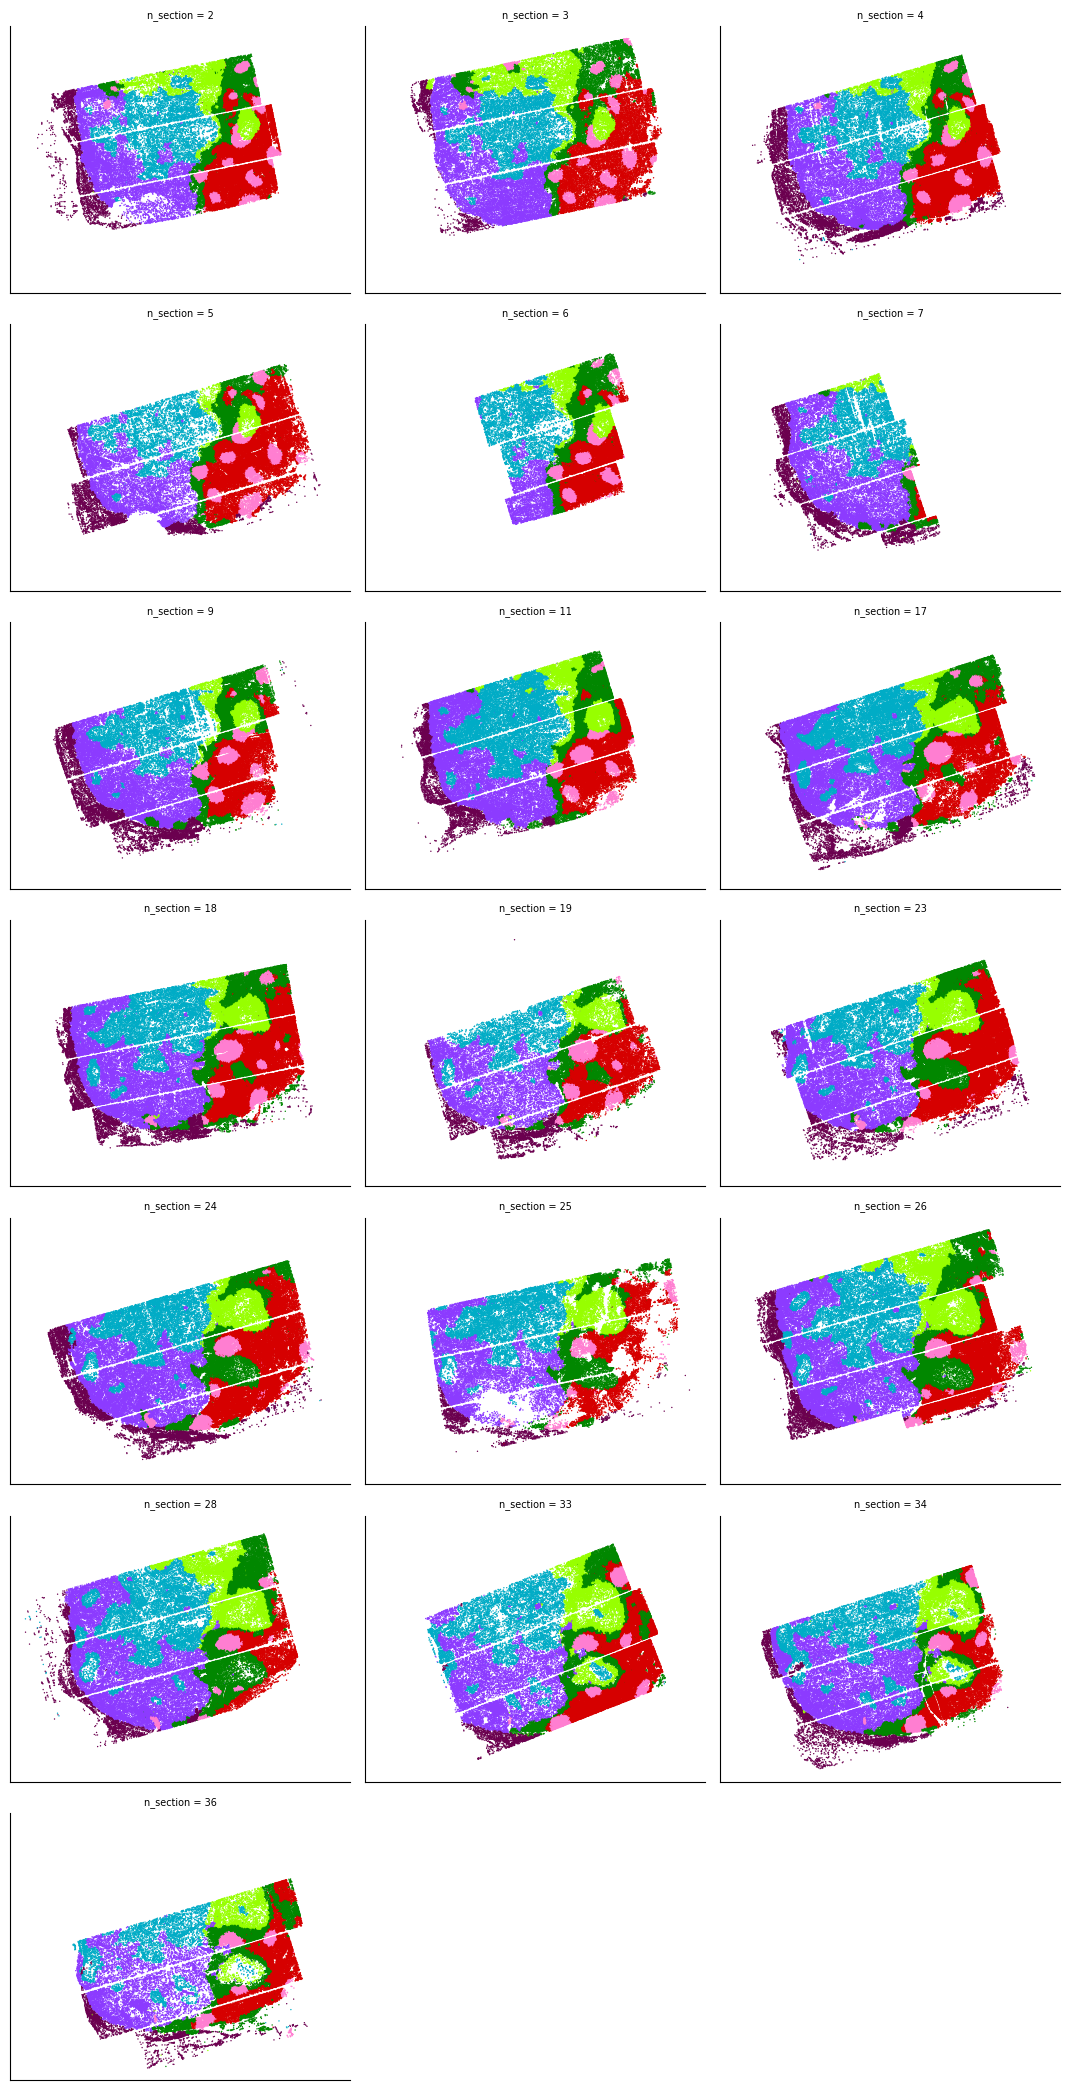

In [17]:
g = sns.FacetGrid(labels, col="n_section", col_wrap=3, aspect=1.2, legend_out=True)
_ = g.map_dataframe(
    sns.scatterplot,
    x="x",
    y="y",
    hue="spatialleiden",
    palette=domain_palette,
    **scatter_kwargs,
)
_ = g.set(aspect=1)
for ax in g.axes.flat:
    remove_tick_and_label(ax)

# g.add_legend(palette)

_ = g.tight_layout()

## GIF

In [18]:
conda_cmd = activate_env_cmd("gif")
script_path = Path("gif") / "gif.py"

In [19]:
batch_key = "n_section"
fps = 2
height = 7

for file in results_lymphnode.glob("*.parquet"):
    out_file = results_lymphnode / f"{file.stem}.gif"
    cmd = (
        f"{script_path} {file} {out_file} "
        f"--batch {batch_key} "
        f"--fps {fps} "
        f"--height {height} "
    )

    subprocess.run(f"{conda_cmd} && {cmd}", shell=True, executable=SHELL, env=env)

# Evaluation


## In and out-of-slice neighbors

In [20]:
adata = ad.read_h5ad(processed_h5ad)

adata.obs = adata.obs.join(labels["spatialleiden"])

In [21]:
from scipy.sparse import csr_matrix

neighbor_stats = []
for g, idx in adata.obs.groupby("n_section").indices.items():
    distances = csr_matrix(adata.obsp["spatial_distances"][idx, :])
    in_slice = distances[:, idx]
    out_of_slice = distances[:, list(set(range(distances.shape[1])) - set(idx))]

    n_in = in_slice.getnnz(axis=1)
    n_out = out_of_slice.getnnz(axis=1)
    mean_in = in_slice.sum(axis=1).A1 / n_in
    mean_out = out_of_slice.sum(axis=1).A1 / n_out

    df = pd.DataFrame(
        {
            "slice": g,
            "mean_dist_in": mean_in,
            "mean_dist_out": mean_out,
            "n_neigh_in": n_in,
            "n_neigh_out": n_out,
        }
    )
    neighbor_stats.append(df)

neighbor_stats = pd.concat(neighbor_stats)

/tmp/ipykernel_883/659260400.py:11: RuntimeWarning: invalid value encountered in divide
  mean_in = in_slice.sum(axis=1).A1 / n_in
/tmp/ipykernel_883/659260400.py:12: RuntimeWarning: invalid value encountered in divide
  mean_out = out_of_slice.sum(axis=1).A1 / n_out


In [22]:
mean_dist = neighbor_stats.melt(
    "slice", ["mean_dist_in", "mean_dist_out"], "in_slice", "mean_dist"
).assign(
    neighbors=lambda df: df["in_slice"].map(
        {"mean_dist_in": "within section", "mean_dist_out": "across sections"}
    )
)
frac_out_neighbors = (
    neighbor_stats.assign(has_out_neighbors=lambda df: df["n_neigh_out"] > 0)
    .groupby(["slice", "has_out_neighbors"], observed=False)
    .size()
    .to_frame("n")
    .reset_index()
    .pivot(columns="has_out_neighbors", index="slice", values="n")
    .assign(fraction=lambda df: df[True] / (df[True] + df[False]))
)

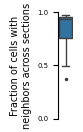

In [23]:
fig, ax = plt.subplots(figsize=(5 * mm, 35 * mm))


_ = sns.boxplot(
    data=frac_out_neighbors,
    y="fraction",
    ax=ax,
    flierprops={"marker": ".", "markerfacecolor": "black", "markersize": 3},
)
_ = ax.set(
    ylabel="Fraction of cells with\nneighbors across sections",
    ylim=(0, 1),
    xticks=[],
    yticks=[0, 0.5, 1],
)
for x in ["top", "right", "bottom"]:
    ax.spines[x].set_visible(False)

fig.savefig(results_lymphnode / "fraction_neighbors.pdf")

In [24]:
import numpy as np

z = np.unique(adata.obsm["spatial_3d_aligned"][:, 2])
dist = np.abs(z - z[None, :].T)
np.fill_diagonal(dist, np.inf)
min_dist = dist.min()

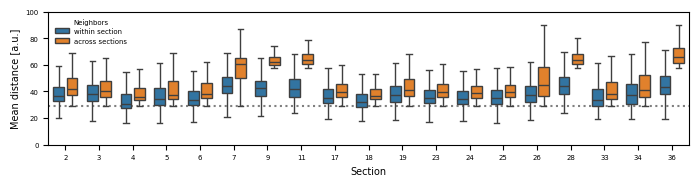

In [25]:
fig, ax = plt.subplots(figsize=(180 * mm, 50 * mm))

_ = ax.axhline(min_dist, color="grey", linestyle="dotted")
_ = sns.boxplot(
    data=mean_dist,
    x="slice",
    y="mean_dist",
    hue="neighbors",
    ax=ax,
    fliersize=0,
    gap=0.2,
    flierprops={"marker": ".", "markerfacecolor": "black"},
)
_ = ax.set(ylim=(0, 100), ylabel="Mean distance [a.u.]", xlabel="Section")
_ = ax.legend_.set(loc="upper left", frame_on=False, title="Neighbors")


fig.tight_layout()
fig.savefig(results_lymphnode / "mean_dist.pdf")

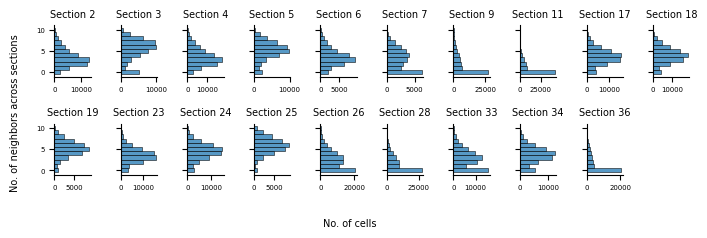

In [26]:
n_neigh = neighbor_stats.melt("slice", ["n_neigh_in", "n_neigh_out"], "in_slice", "n")

n = adata.obs["n_section"].nunique()
wrap = int(ceil(n / 2))

aspect = 0.6
height = 180 * mm / wrap / aspect

g = sns.FacetGrid(
    n_neigh.loc[lambda df: df["in_slice"] == "n_neigh_out"],
    col_wrap=wrap,
    col="slice",
    height=height,
    aspect=aspect,
    sharey=True,
    sharex=False,
)
_ = g.map_dataframe(sns.histplot, y="n", discrete=True)
_ = g.set_titles(col_template="Section {col_name}")
_ = g.set_axis_labels(x_var="", y_var="")
g.fig.supxlabel("No. of cells", fontsize=fontsize_l)
g.fig.supylabel("No. of neighbors across sections", fontsize=fontsize_l)
_ = g.set(yticks=[0, 5, 10])

_ = g.tight_layout()
g.savefig(results_lymphnode / "neighbor_distribution.pdf")

## Domain compositions

In [27]:
def stacked_barplot(ax, data, x, y, hue, palette, legend=False):
    import numpy as np

    bottoms = np.zeros(data[x].unique().size)
    x_max = data[x].max() + 0.5

    for c, df in data.groupby(hue):
        ax.bar(df[x], df[y], 1, label=c, bottom=bottoms, color=palette[c])
        bottoms += df[y].to_numpy()

    ax.set(ylim=(0, 1), xlim=(0.5, x_max), xlabel=x, ylabel=y)
    if legend:
        ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), ncol=2)


def fraction_of_labels(df, batch, label):
    df = df.groupby([batch, label], observed=False).size().to_frame("n").reset_index()
    df["fraction"] = df["n"] / df.groupby(batch)["n"].transform("sum")
    return df

In [28]:
# rename celltypes
rename_ct = {
    "Cortex_CCL21": "CCL21",
    "Plasma_IgG": "IgG",
    "Plasma_IgA": "IgA",
    "M1_macrophages": "M1",
    "Macrophages": "Macro",
    "Fibroblasts": "Fibro",
    "Germinal_Center_Plasma_IgM_B_cell": "GC",
    "T_cell": "T cell",
    "High_Endothelial_Venules": "Endo",
    "Tumor_Keratin_Pearl": "Keratin",
    "Cytotoxic_IFN_signaling": "Cyto",
    "Mast_cells": "Mast cells",
    "Dendritic_cells": "DC",
}

adata.obs["manual_anno"] = adata.obs["annotation"].cat.rename_categories(rename_ct)

celltype_palette = dict(zip(adata.obs["manual_anno"].cat.categories, cc.glasbey_light))

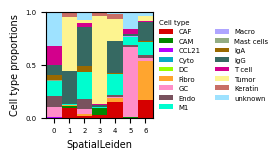

In [29]:
batch = "spatialleiden"
anno = "manual_anno"


frac = fraction_of_labels(
    adata.obs[[batch, anno]].assign(**{batch: lambda df: df[batch].cat.as_ordered()}),
    batch,
    anno,
)

fig, ax = plt.subplots(figsize=(35 * mm, 35 * mm))
stacked_barplot(
    ax, frac, batch, "fraction", hue=anno, palette=celltype_palette, legend=True
)

_ = ax.set(xlabel="SpatialLeiden", ylabel="Cell type proportions")
_ = ax.legend_.set_frame_on(False)
_ = ax.legend_.set_title("Cell type")
_ = ax.legend_.set_alignment("left")
_ = ax.set(
    yticks=[0, 0.5, 1],
    xticks=range(adata.obs[batch].cat.categories.size),
    xlim=(-0.5, None),
)

fig.savefig(results_lymphnode / "celltype_composition_domain.pdf")

In [30]:
stack_dir = results_lymphnode / "stack"

stack_dir.mkdir(parents=True, exist_ok=True)

In [31]:
labels = adata.obs[["spatialleiden", "n_section", "manual_anno"]].copy()
labels.loc[:, ["x", "y", "z"]] = adata.obsm["spatial_3d_aligned"].copy()

In [32]:
scatter_kwargs = {"s": 1, "linewidth": 0, "legend": False}

xlim = (labels["x"].min(), labels["x"].max())
ylim = (labels["y"].min(), labels["y"].max())

for n, df in labels.groupby("n_section"):
    fig, ax = plt.subplots()
    sns.scatterplot(
        data=df,
        x="x",
        y="y",
        hue="spatialleiden",
        palette=domain_palette,
        ax=ax,
        **scatter_kwargs,
    )

    _ = ax.set(aspect=1, xlim=xlim, ylim=ylim)
    ax.axis("off")

    fig.tight_layout()
    fig.savefig(stack_dir / f"{n}.png", dpi=300)
    plt.close()

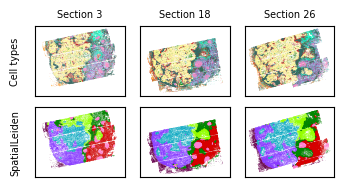

In [33]:
examples = [3, 18, 26]

scatter_kwargs = {"s": 0.05, "linewidth": 0, "legend": False, "rasterized": True}

fig, axs = plt.subplots(
    ncols=3, nrows=2, sharex=True, sharey=True, figsize=(90 * mm, 50 * mm)
)

for i, n in enumerate(examples):
    df = labels.loc[lambda df: df["n_section"] == n]
    sns.scatterplot(
        data=df,
        x="x",
        y="y",
        hue="spatialleiden",
        palette=domain_palette,
        ax=axs[1, i],
        **scatter_kwargs,
    )
    sns.scatterplot(
        data=df,
        x="x",
        y="y",
        hue="manual_anno",
        palette=celltype_palette,
        ax=axs[0, i],
        **scatter_kwargs,
    )
    axs[0, i].set(title=f"Section {n}")

for ax in axs.ravel():
    _ = ax.set(aspect=1)
    remove_tick_and_label(ax)

axs[0, 0].set(ylabel="Cell types")
axs[1, 0].set(ylabel="SpatialLeiden")

fig.tight_layout()
fig.savefig(results_lymphnode / "example_sections.pdf", dpi=600)

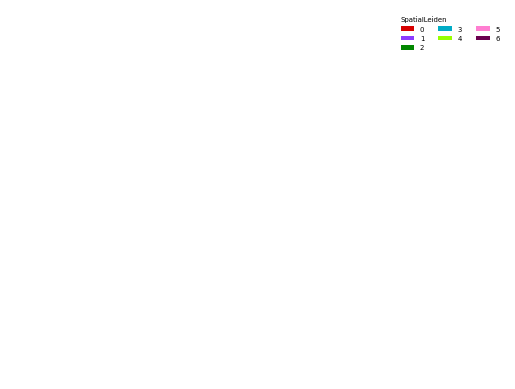

In [34]:
from matplotlib.patches import Patch

fig, ax = plt.subplots()

handles = [
    Patch(facecolor=color, label=label) for label, color in domain_palette.items()
]

# Add legend with title
ax.legend(handles=handles, title="SpatialLeiden", frameon=False, ncol=3)
_ = ax.legend_.set_alignment("left")
_ = ax.axis("off")
fig.savefig(results_lymphnode / "domain_legend.pdf")